# 01 · Exploración de los datos de Olist

**Objetivo de este notebook:** entender qué hay en cada tabla y detectar problemas **antes de limpiar nada**.
Aquí no se modifica ningún dato: solo se mira, se mide y se anota.


## 0. Carga de las 9 tablas

- **Path** es nuevo: sirve para manejar rutas de archivos de forma limpia

- **Opciones de pandas**:

  pd.set_option("display.max_columns", 30)
 
  pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

  
    Son ajustes de cómo se muestra la tabla, no cambian los datos.
    La primera evita que pandas oculte columnas con ... cuando hay muchas. Enseña hasta 30.
    La segunda fuerza que todos los decimales salgan con 2 cifras y separador de miles (16,008,872.12 en vez de 1.6008872e+07). lambda x: ... es una función de una línea, igual que f(x) = ...; recibe cada número x y devuelve el texto formateado.


- **La ruta**:

  RAW = Path("../data/raw")

  Guarda en una variable la carpeta de los datos. ../ significa “sube una carpeta” (el notebook está en notebooks/ y los datos en data/raw/). Ventaja: la ruta es relativa, así que el proyecto funciona igual si lo mueves de sitio o lo descarga otra persona de GitHub. Una ruta como C:\Users\david\... solo funcionaría en tu equipo.

    Además, Path permite unir rutas con /: RAW / "archivo.csv" equivale a "../data/raw/archivo.csv", sin preocuparte de barras \ o /.


- **El diccionario de ficheros:**

  Un diccionario: cada clave es un nombre corto que he elegido ("customers") y cada valor es el nombre real del archivo. Lo hago porque los nombres reales son largos y repetitivos. Luego prefieres escribir t["customers"] en vez de olist_customers_dataset.

- **La carga:**

  t = {nombre: pd.read_csv(RAW / f) for nombre, f in ficheros.items()}

  Es un bucle escrito en una línea, lo mismo que:

        t = {}
        for nombre, f in ficheros.items():
        t[nombre] = pd.read_csv(RAW / f)

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RAW = Path("../data/raw")

ficheros = {
    "customers":   "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "items":       "olist_order_items_dataset.csv",
    "payments":    "olist_order_payments_dataset.csv",
    "reviews":     "olist_order_reviews_dataset.csv",
    "orders":      "olist_orders_dataset.csv",
    "products":    "olist_products_dataset.csv",
    "sellers":     "olist_sellers_dataset.csv",
    "translation": "product_category_name_translation.csv",
}

t = {nombre: pd.read_csv(RAW / f) for nombre, f in ficheros.items()}

list(t)

['customers',
 'geolocation',
 'items',
 'payments',
 'reviews',
 'orders',
 'products',
 'sellers',
 'translation']

## 1. Vista general

Una tabla es como una hoja de Excel: **una fila = una "cosa"** (un pedido, un artículo, un pago...).
Saber qué es exactamente una fila (lo que en bases de datos se llama la **granularidad** de la tabla) es lo más importante
para no equivocarse luego al unir tablas.

Aquí hacemos un resumen rápido para visualizar las tablas con las que vamos a trabajar.

- **El bucle**. for k, d in t.items() recorre las 9 tablas. En cada vuelta, k es el nombre corto ("orders") y d es el DataFrame.

- **El diccionario pequeño**. Para cada tabla se construye un diccionario con 4 medidas:

    "filas" -> len(d): número de filas

    "columnas " -> d.shape[1]. shape es la tupla (fila, columna), con [1] cogemos las columnas

    "nulos_totales" -> d.isna() da una tabla de True/False. El primer .sum() cuenta los True por columna y el segundo suma esas columnas. Con int() convertimos a entero normal.

    "filas_duplicadas" -> d.duplicated() marca como True las filas que son copia exacta de una anterior y .sum() las cuenta

- **El diccionario grande**. k: {...} guarda, para cada tabla, ese diccionario de 4 medidas. Queda algo así:

        {"customers": {"filas": 99441, "columnas": 5, ...},
        "orders":    {"filas": 99441, "columnas": 8, ...}, ...}

- **pd.DataFrame(...)**. Convierte ese diccionario en tabla. Pandas coloca las claves del diccionario grande como columnas, así que saldría con las tablas en horizontal y las medidas en vertical.

- **.T**. Es la transpuesta, igual que en álgebra lineal: intercambia filas y columnas. Así queda una fila por tabla y una columna por medida, que se lee mejor.
  

El bucle normal (más largo) sería:

    filas_resumen = []
    for nombre, d in t.items():
        filas_resumen.append({
            "tabla": nombre,
            "filas": len(d),
            "columnas": d.shape[1],
            "nulos_totales": int(d.isna().sum().sum()),
            "filas_duplicadas": int(d.duplicated().sum()),
        })
    resumen = pd.DataFrame(filas_resumen).set_index("tabla")

In [50]:
resumen = pd.DataFrame({
    k: {
        "filas": len(d),
        "columnas": d.shape[1],
        "nulos_totales": int(d.isna().sum().sum()),
        "filas_duplicadas": int(d.duplicated().sum()),
    }
    for k, d in t.items()
}).T

resumen

,filas,columnas,nulos_totales,filas_duplicadas
customers,99441,5,0,0
geolocation,1000163,5,0,261831
items,112650,7,0,0
payments,103886,5,0,0
reviews,99224,7,145903,0
orders,99441,8,4908,0
products,32951,9,2448,0
sellers,3095,4,0,0
translation,71,2,0,0


## 2. Claves: ¿qué identifica de forma única una fila?

- **Clave primaria:** la columna (o combinación de columnas) que no se repite en ninguna fila de su tabla. Es el "DNI" de cada fila.
- **Clave foránea:** una columna que contiene la clave primaria de *otra* tabla. Así se relacionan las tablas
  (por ejemplo `orders.customer_id` apunta a `customers.customer_id`).

Comprobemos cuáles son las claves candidatas y si de verdad son únicas.

In [53]:
claves = {
    "customers":   ["customer_id"],
    "orders":      ["order_id"],
    "items":       ["order_id", "order_item_id"],
    "payments":    ["order_id", "payment_sequential"],
    "reviews":     ["review_id"],
    "products":    ["product_id"],
    "sellers":     ["seller_id"],
    "translation": ["product_category_name"],
}

for nombre, cols in claves.items():
    repetidas = t[nombre].duplicated(subset=cols).sum()
    print(f"{nombre:12} clave {str(cols):38} filas repetidas: {repetidas}")

customers    clave ['customer_id']                        filas repetidas: 0
orders       clave ['order_id']                           filas repetidas: 0
items        clave ['order_id', 'order_item_id']          filas repetidas: 0
payments     clave ['order_id', 'payment_sequential']     filas repetidas: 0
reviews      clave ['review_id']                          filas repetidas: 814
products     clave ['product_id']                         filas repetidas: 0
sellers      clave ['seller_id']                          filas repetidas: 0
translation  clave ['product_category_name']              filas repetidas: 0


**Tu turno:** ¿alguna clave no es única? Si es así, ¿qué significa para el análisis?
(Pista: mira `reviews`. Lo investigamos en la sección 6.)

Vemos que en la tabla reviews no existe clave primaria, ya que no es única. Supongo que esto quiere decir que la gente pone mas de una review por persona? por lo tanto no tiene sentido separar por review_id aqui.

**Respuesta correcta**: Todas las claves son únicas excepto review_id en reviews, que tiene 814 valores repetidos, así que no es clave primaria. Al mirar los casos, el mismo review_id aparece en pedidos distintos (order_id diferentes) con la misma nota y la misma fecha, lo que sugiere que una sola reseña se ha asociado a varios pedidos. Además, order_id tampoco es único en reviews: algunos pedidos tienen varias reseñas distintas. La clave real de la tabla es la combinación (review_id, order_id).

Implicación para el análisis: reviews no tiene una fila por pedido. Si la uno con orders sin tratarla antes, los pedidos con varias reseñas aparecerán duplicados y falsearán conteos, medias y totales. Antes de unirla habrá que reducirla a una reseña por pedido, y decidir con qué criterio (la más reciente, la media, la peor...).

## 3. Clientes: `customer_id` frente a `customer_unique_id`

Esta es la trampa clásica de este dataset. En `customers` hay **dos** identificadores.

In [65]:
c = t["customers"] #solo da un nombre corto a la tabla

print("filas en customers:             ", len(c))
print("valores distintos de customer_id:       ", c.customer_id.nunique()) 
#.nunique() cuenta valores distintos de una columna

print("valores distintos de customer_unique_id:", c.customer_unique_id.nunique())

filas en customers:              99441
valores distintos de customer_id:        99441
valores distintos de customer_unique_id: 96096


In [67]:
pedidos_por_persona = (
    t["orders"].merge(c, on="customer_id")
    .groupby("customer_unique_id").order_id.nunique()
)

print(pedidos_por_persona.value_counts().sort_index())
print(f"\n% de personas que han comprado más de una vez: {(pedidos_por_persona > 1).mean():.1%}")

order_id
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

% de personas que han comprado más de una vez: 3.1%


- **Merge:** une las dos tablas por customer_id distintos
  
        t["orders"].merge(c, on="customer_id")

- **Groupby:** agrupa las filas por persona y, dentro de cada grupo, cuenta los order_id distintos:

        .groupby("customer_unique_id").order_id.nunique()

Vemos esto con un ejemplo sencillo:

In [71]:
import pandas as pd

# Tablas de juguete: Ana compra 2 veces (con dos customer_id distintos), Luis 1 vez
orders_demo = pd.DataFrame({
    "order_id":    ["P1", "P2", "P3"],
    "customer_id": ["a1", "a2", "b1"],
})
customers_demo = pd.DataFrame({
    "customer_id":        ["a1", "a2", "b1"],
    "customer_unique_id": ["Ana", "Ana", "Luis"],
})

# Paso 1: a cada pedido le pegamos la persona real (unimos por customer_id)
paso1 = orders_demo.merge(customers_demo, on="customer_id")
print(paso1, "\n")

# Paso 2: agrupamos por persona y contamos pedidos distintos de cada una
paso2 = paso1.groupby("customer_unique_id").order_id.nunique()
print(paso2, "\n")

# Paso 3: cuántas personas hay con 1 pedido, con 2, con 3...
print(paso2.value_counts().sort_index(), "\n")

# Paso 4: proporción de personas con más de 1 pedido (True=1, False=0, la media es la proporción)
print((paso2 > 1).mean())

  order_id customer_id customer_unique_id
0       P1          a1                Ana
1       P2          a2                Ana
2       P3          b1               Luis 

customer_unique_id
Ana     2
Luis    1
Name: order_id, dtype: int64 

order_id
1    1
2    1
Name: count, dtype: int64 

0.5


**Tu turno:** ¿por qué `customer_id` tiene tantos valores distintos como filas? ¿Qué error se cometería en la pregunta 5
("¿cuántos compradores repiten?") si usaras `customer_id`?

customer id tiene tantos valores distintos porque se esta guardando con un id distinto a personas que compran mas de una vez. Si sumaramos estos tendriamos en cuenta mas de los reales, por eso debemos usar customer_id_unique

**Respuesta correcta:** customer_id tiene tantos valores distintos como filas (99.441) porque Olist genera uno nuevo en cada pedido, aunque lo haga la misma persona. La persona real se identifica con customer_unique_id, que tiene 96.096 valores distintos.

Si usara customer_id para la pregunta 5, cada pedido parecería de un cliente diferente: sobrestimaría el número de clientes (99.441 en vez de 96.096) y, sobre todo, nunca detectaría a nadie que repite compra, lo que haría parecer que la recompra es 0%. Para medir la recompra hay que agrupar por customer_unique_id. Con él, el 3,1% de las personas compró más de una vez.

## 4. Pedidos: estados, fechas y nulos

Las fechas vienen como texto. Las convertimos **en una copia** solo para poder mirarlas (la limpieza real vendrá después).

In [79]:
cols_fecha = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]

o = t["orders"].copy()

for col in cols_fecha:
    o[col] = pd.to_datetime(o[col])

print(o.order_status.value_counts())
print("\nRango de fechas de compra:", o.order_purchase_timestamp.min(), "->", o.order_purchase_timestamp.max())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Rango de fechas de compra: 2016-09-04 21:15:19 -> 2018-10-17 17:30:18


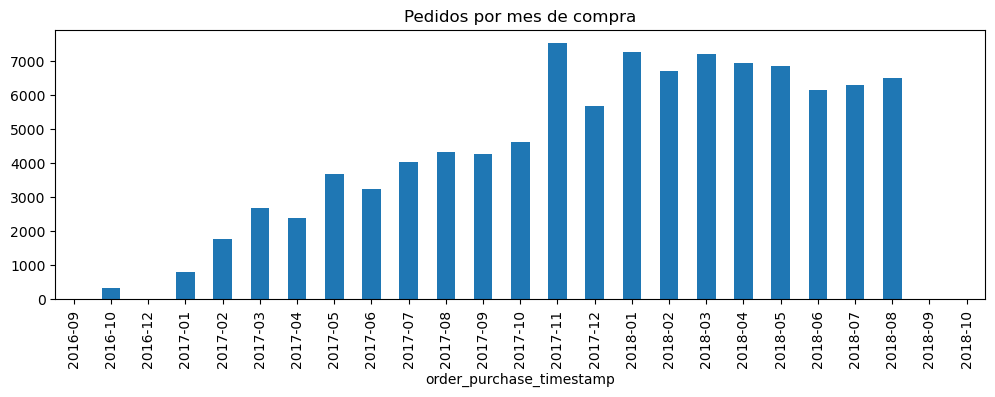

(order_purchase_timestamp
 2016-09       4
 2016-10     324
 2016-12       1
 2017-01     800
 2017-02    1780
 2017-03    2682
 Freq: M, dtype: int64,
 order_purchase_timestamp
 2018-07    6292
 2018-08    6512
 2018-09      16
 2018-10       4
 Freq: M, dtype: int64)

In [82]:
pedidos_mes = o.groupby(o.order_purchase_timestamp.dt.to_period("M")).size()
pedidos_mes.plot(kind="bar", figsize=(12, 3.5), title="Pedidos por mes de compra")
plt.show()
pedidos_mes.head(6), pedidos_mes.tail(4)

Los nulos de las fechas de pedidos: ¿son errores o tienen explicación? Si un pedido está *cancelled*, es lógico que
no tenga fecha de entrega. Cruzamos nulos con estado:

In [84]:
nulos_por_estado = o.set_index("order_status")[cols_fecha].isna().groupby(level=0).sum()
nulos_por_estado["n_pedidos"] = o.order_status.value_counts()
nulos_por_estado

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,n_pedidos
order_status,,,,,,
approved,0,0,2,2,0,2
canceled,0,141,550,619,0,625
created,0,5,5,5,0,5
delivered,0,14,2,8,0,96478
invoiced,0,0,314,314,0,314
processing,0,0,301,301,0,301
shipped,0,0,0,1107,0,1107
unavailable,0,0,609,609,0,609


**Tu turno:** ¿qué nulos tienen explicación lógica y cuáles son sospechosos (p. ej. pedidos *delivered* sin fecha de entrega)?
¿Rellenarías esos nulos? ¿Por qué sí o por qué no?

> _Escribe aquí tu respuesta._

### Coherencia temporal: ¿el orden de las fechas tiene sentido?

In [88]:
ent = o.order_delivered_customer_date
print("delivered sin fecha de entrega al cliente:      ", ((o.order_status == "delivered") & ent.isna()).sum())
print("entrega al cliente anterior a la compra:         ", (ent < o.order_purchase_timestamp).sum())
print("entrega al transportista anterior a la aprobación:", (o.order_delivered_carrier_date < o.order_approved_at).sum())
print("entrega al cliente anterior a la del transportista:", (ent < o.order_delivered_carrier_date).sum())

delivered sin fecha de entrega al cliente:       8
entrega al cliente anterior a la compra:          0
entrega al transportista anterior a la aprobación: 1359
entrega al cliente anterior a la del transportista: 23


### Adelanto de la pregunta 3: retraso de entrega

`retraso = fecha real de entrega - fecha estimada`. Positivo = llegó tarde. (El cálculo definitivo lo haremos en SQL;
aquí solo queremos ver si el dato es usable.)

% de pedidos entregados con retraso: 8.1%
count   96,470.00
mean       -11.18
std         10.18
min       -146.02
25%        -16.24
50%        -11.95
75%         -6.39
max        188.98
Name: dias_retraso, dtype: float64


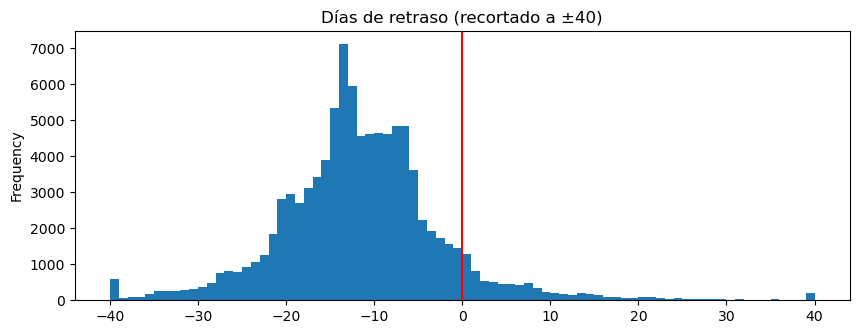

In [91]:
entregados = o[(o.order_status == "delivered") & o.order_delivered_customer_date.notna()].copy()
entregados["dias_retraso"] = (
    entregados.order_delivered_customer_date - entregados.order_estimated_delivery_date
).dt.total_seconds() / 86400

print(f"% de pedidos entregados con retraso: {(entregados.dias_retraso > 0).mean():.1%}")
print(entregados.dias_retraso.describe())

entregados.dias_retraso.clip(-40, 40).plot(kind="hist", bins=80, figsize=(10, 3.5),
                                            title="Días de retraso (recortado a ±40)")
plt.axvline(0, color="red")
plt.show()

## 5. Artículos (`items`): precios y fletes

Una fila de `items` es **un artículo dentro de un pedido**, no un pedido. Un pedido con 3 artículos tiene 3 filas.

In [94]:
it = t["items"]
print("pedidos distintos en items:", it.order_id.nunique(), "| filas:", len(it))
print("pedidos sin ningún artículo:", (~o.order_id.isin(it.order_id)).sum())
print("artículos con producto inexistente:", (~it.product_id.isin(t["products"].product_id)).sum())
print("artículos con vendedor inexistente:", (~it.seller_id.isin(t["sellers"].seller_id)).sum())
print("precios <= 0:", (it.price <= 0).sum())
it[["price", "freight_value"]].describe()

pedidos distintos en items: 98666 | filas: 112650
pedidos sin ningún artículo: 775
artículos con producto inexistente: 0
artículos con vendedor inexistente: 0
precios <= 0: 0


,price,freight_value
count,"112,650.00","112,650.00"
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
25%,39.90,13.08
50%,74.99,16.26
75%,134.90,21.15
max,"6,735.00",409.68


## 6. Reseñas

Esperamos 1 reseña por pedido. Comprobemos si es cierto.

In [97]:
r = t["reviews"]
print("review_id repetidos:", r.review_id.duplicated().sum())
print("pedidos con más de una reseña:", (r.groupby("order_id").size() > 1).sum())
print("pedidos sin ninguna reseña:", (~o.order_id.isin(r.order_id)).sum())
print()
print(r.review_score.value_counts(normalize=True).sort_index().map("{:.1%}".format))

review_id repetidos: 814
pedidos con más de una reseña: 547
pedidos sin ninguna reseña: 768

review_score
1    11.5%
2     3.2%
3     8.2%
4    19.3%
5    57.8%
Name: proportion, dtype: object


**Tu turno:** si un pedido tiene 2 reseñas y luego unes `orders` con `reviews`, ¿qué le pasa al número de filas?
¿Cómo decidirías cuál conservar? (Opciones: la más reciente, la media, la peor...) Razona tu elección.

> _Escribe aquí tu respuesta._

## 7. Pagos y el peligro de multiplicar filas

Un pedido puede pagarse con varios métodos (tarjeta + vale) y por tanto tener varias filas en `payments`.
Esto causa el error más común al unir tablas: **la multiplicación de filas** ("fan-out").

In [101]:
p = t["payments"]
print(p.payment_type.value_counts())
print("\nFilas de pago por pedido:")
print(p.groupby("order_id").size().value_counts().sort_index())

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

Filas de pago por pedido:
1     96479
2      2382
3       301
4       108
5        52
6        36
7        28
8        11
9         9
10        5
11        8
12        8
13        3
14        2
15        2
19        2
21        1
22        1
26        1
29        1
Name: count, dtype: int64


In [103]:
# Demostración del error: unimos pedidos -> artículos -> pagos y sumamos el dinero cobrado
total_real = p.payment_value.sum()

mal = (
    o[["order_id"]]
    .merge(t["items"][["order_id", "order_item_id"]], on="order_id")
    .merge(p, on="order_id")
)
print(f"Total cobrado real:          {total_real:>14,.2f}")
print(f"Total tras unir mal las tablas: {mal.payment_value.sum():>11,.2f}")
print(f"Sobreestimación:             {mal.payment_value.sum() / total_real - 1:>14.1%}")

Total cobrado real:           16,008,872.12
Total tras unir mal las tablas: 20,308,134.71
Sobreestimación:                      26.9%


**Tu turno:** explica con tus palabras por qué se infla el total. ¿Cómo se evitaría? (Pista: agregar `payments` a
un valor por pedido *antes* de unir.)

> _Escribe aquí tu respuesta._

## 8. Productos y categorías

In [107]:
pr = t["products"].merge(t["translation"], on="product_category_name", how="left")
print("productos sin categoría:", pr.product_category_name.isna().sum())
sin_trad = pr[pr.product_category_name.notna() & pr.product_category_name_english.isna()]
print("productos con categoría pero SIN traducción al inglés:", len(sin_trad))
print(sin_trad.product_category_name.value_counts())
print("\npeso = 0 g:", (pr.product_weight_g == 0).sum())
print("categorías distintas:", pr.product_category_name.nunique())

productos sin categoría: 610
productos con categoría pero SIN traducción al inglés: 13
product_category_name
portateis_cozinha_e_preparadores_de_alimentos    10
pc_gamer                                          3
Name: count, dtype: int64

peso = 0 g: 4
categorías distintas: 73


## 9. Geolocalización

In [110]:
g = t["geolocation"]
print("filas:", len(g), "| códigos postales distintos:", g.geolocation_zip_code_prefix.nunique())
print("\nFilas por código postal:")
print(g.groupby("geolocation_zip_code_prefix").size().describe())

fuera = ~g.geolocation_lat.between(-34, 6) | ~g.geolocation_lng.between(-74, -34)
print("\ncoordenadas fuera del rectángulo de Brasil:", fuera.sum())
print("clientes con código postal sin geolocalización:",
      (~t["customers"].customer_zip_code_prefix.isin(g.geolocation_zip_code_prefix)).sum())

filas: 1000163 | códigos postales distintos: 19015

Filas por código postal:
count   19,015.00
mean        52.60
std         72.06
min          1.00
25%         10.00
50%         29.00
75%         66.50
max      1,146.00
dtype: float64

coordenadas fuera del rectángulo de Brasil: 42
clientes con código postal sin geolocalización: 278


## 10. Resumen de hallazgos (rellénalo tú)

Cuando hayas ejecutado todo, completa esta tabla. Es la base del siguiente notebook (limpieza).

| Tabla | Problema detectado | Decisión que propongo |
|---|---|---|
| orders | | |
| customers | | |
| reviews | | |
| payments | | |
| products | | |
| geolocation | | |